In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("../data/project_portfolio_history.csv")

In [4]:
df.head(

)

,Project_ID,Portfolio_Segment,Region,Delivery_Model,Planning_Mode,Complexity_Score,Planned_Duration_Days,Actual_Duration_Days,Delay_Days,Delay_Flag,...,Critical_Path_Task_Count,Vendor_Count,Change_Order_Count,Resource_Buffer_Pct,Weather_Risk_Index,Procurement_Risk_Index,Stakeholder_Alignment_Score,Requirements_Volatility_Score,Forecast_Error_Days,Outcome_Risk_Level
0,P001,Public Sector,South,Design-Build,Spreadsheet,69,301,296,-5,On Time,...,12,11,4,8.3,5.0,35.1,68.1,31.7,3,Low
1,P002,Infrastructure,Central,Design-Build,Spreadsheet,63,266,267,1,Delayed,...,11,8,7,12.0,10.3,7.0,60.2,56.6,1,Low
2,P003,Commercial,North,Agile Hybrid,Spreadsheet,68,304,304,0,On Time,...,14,10,4,4.4,40.9,72.5,52.9,43.3,2,Medium
3,P004,Commercial,West,EPC,Spreadsheet,50,244,245,1,Delayed,...,10,9,2,11.2,22.4,52.3,57.7,35.6,1,Low
4,P005,Industrial,South,Design-Build,Manual,61,292,299,7,Delayed,...,10,5,7,2.4,35.2,25.8,53.5,44.2,11,Low


In [5]:
df.describe()

,Complexity_Score,Planned_Duration_Days,Actual_Duration_Days,Delay_Days,Planned_Budget_USD,Actual_Budget_USD,Budget_Overrun_Pct,Team_Size,Critical_Path_Task_Count,Vendor_Count,Change_Order_Count,Resource_Buffer_Pct,Weather_Risk_Index,Procurement_Risk_Index,Stakeholder_Alignment_Score,Requirements_Volatility_Score,Forecast_Error_Days
count,360.000000,360.000000,360.000000,360.000000,3.600000e+02,3.600000e+02,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000
mean,63.061111,276.752778,284.613889,7.861111,4.549037e+06,5.150105e+06,12.949000,21.658333,10.255556,6.691667,3.694444,9.254722,37.956944,45.437500,59.816389,47.720833,15.202778
std,11.782932,38.755968,48.612656,17.248233,6.914357e+05,8.967149e+05,5.649562,4.475553,2.281382,2.058189,1.669311,4.227477,19.881775,20.383137,10.170082,10.875924,12.058839
min,27.000000,162.000000,149.000000,-30.000000,2.778423e+06,2.699848e+06,-3.680000,11.000000,5.000000,1.000000,0.000000,2.000000,5.000000,7.000000,31.700000,12.400000,1.000000
25%,55.000000,253.000000,253.750000,-4.000000,4.063100e+06,4.564161e+06,9.315000,19.000000,9.000000,5.000000,3.000000,6.100000,21.875000,29.300000,52.300000,40.475000,6.750000
50%,63.000000,276.500000,282.000000,8.000000,4.541364e+06,5.051349e+06,12.680000,21.500000,10.000000,7.000000,4.000000,9.100000,36.950000,45.050000,59.500000,47.350000,14.000000
75%,71.000000,305.000000,318.250000,19.000000,5.025256e+06,5.749992e+06,17.140000,25.000000,12.000000,8.000000,5.000000,12.300000,52.250000,61.725000,66.825000,55.850000,21.000000
max,96.000000,371.000000,427.000000,64.000000,6.432920e+06,8.016129e+06,33.430000,34.000000,16.000000,14.000000,8.000000,22.000000,88.400000,91.900000,96.000000,73.600000,76.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Project_ID                     360 non-null    object 
 1   Portfolio_Segment              360 non-null    object 
 2   Region                         360 non-null    object 
 3   Delivery_Model                 360 non-null    object 
 4   Planning_Mode                  360 non-null    object 
 5   Complexity_Score               360 non-null    int64  
 6   Planned_Duration_Days          360 non-null    int64  
 7   Actual_Duration_Days           360 non-null    int64  
 8   Delay_Days                     360 non-null    int64  
 9   Delay_Flag                     360 non-null    object 
 10  Planned_Budget_USD             360 non-null    float64
 11  Actual_Budget_USD              360 non-null    float64
 12  Budget_Overrun_Pct             360 non-null    flo

In [7]:
r, c = df.shape
r

360

In [8]:
c

24

In [9]:
plt.figure(figsize=(12, 6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

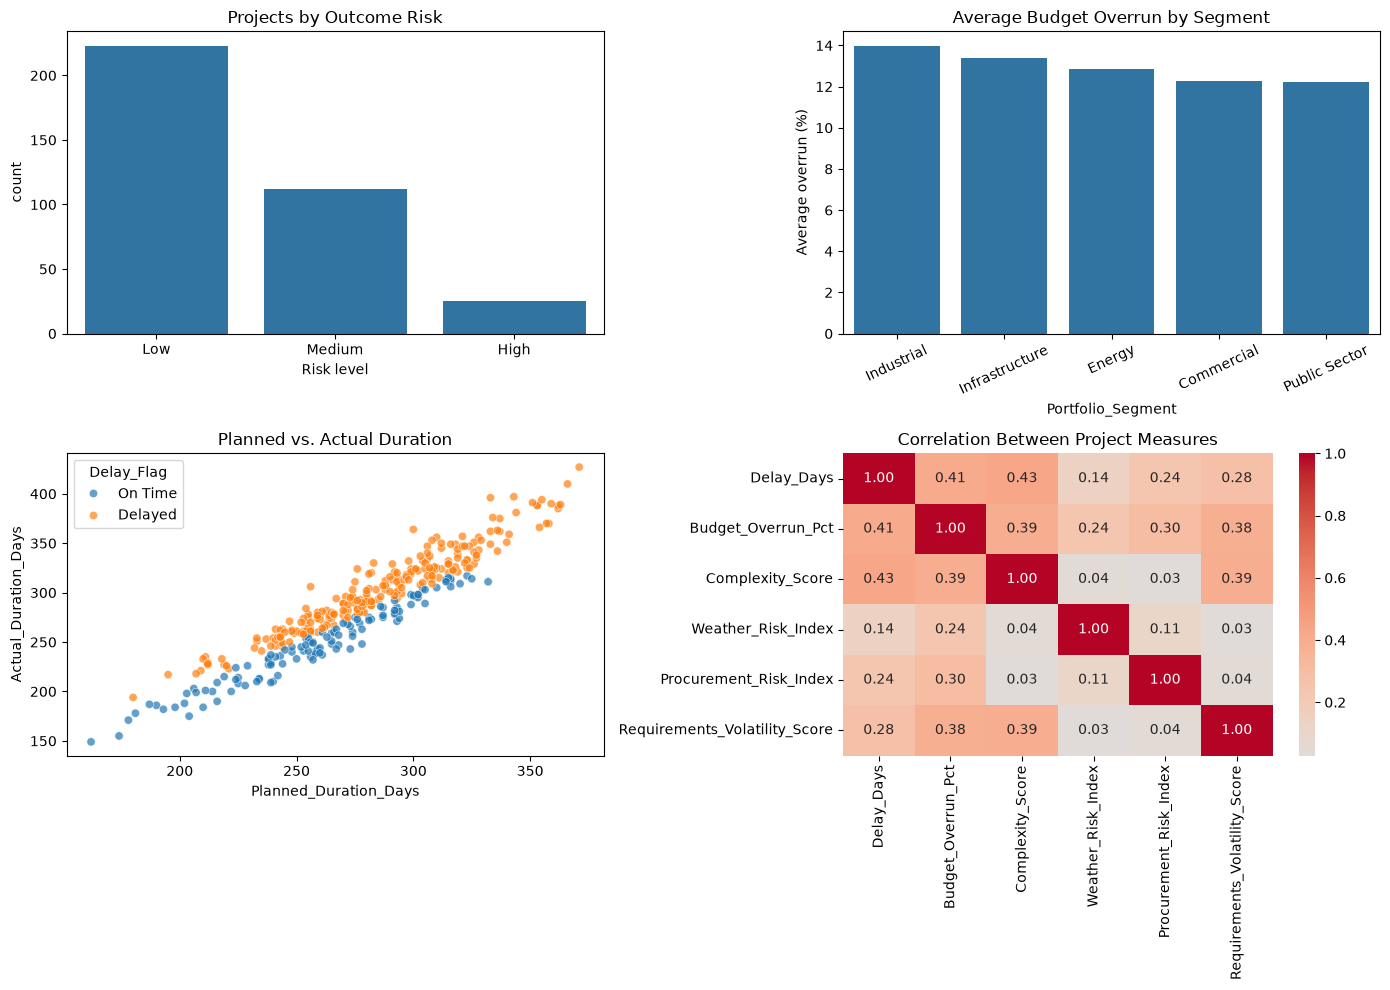

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Project counts by outcome risk
sns.countplot(
    data=df, x="Outcome_Risk_Level",
    order=df["Outcome_Risk_Level"].value_counts().index,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Projects by Outcome Risk")
axes[0, 0].set_xlabel("Risk level")

# Average budget overrun by portfolio segment
overrun = (
    df.groupby("Portfolio_Segment", as_index=False)["Budget_Overrun_Pct"]
      .mean()
      .sort_values("Budget_Overrun_Pct", ascending=False)
)
sns.barplot(data=overrun, x="Portfolio_Segment", y="Budget_Overrun_Pct", ax=axes[0, 1])
axes[0, 1].set_title("Average Budget Overrun by Segment")
axes[0, 1].set_ylabel("Average overrun (%)")
axes[0, 1].tick_params(axis="x", rotation=25)

# Planned vs. actual project duration
sns.scatterplot(
    data=df, x="Planned_Duration_Days", y="Actual_Duration_Days",
    hue="Delay_Flag", alpha=0.7, ax=axes[1, 0]
)
axes[1, 0].set_title("Planned vs. Actual Duration")

# Correlations between selected numeric measures
metrics = [
    "Delay_Days", "Budget_Overrun_Pct", "Complexity_Score",
    "Weather_Risk_Index", "Procurement_Risk_Index",
    "Requirements_Volatility_Score"
]
sns.heatmap(df[metrics].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Between Project Measures")

plt.tight_layout()
plt.show()

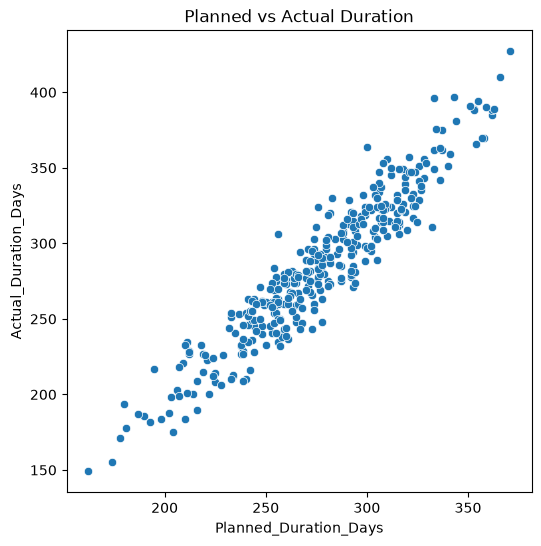

In [12]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    x="Planned_Duration_Days",
    y="Actual_Duration_Days",
    data=df
)

plt.title("Planned vs Actual Duration")
plt.show()

<Axes: xlabel='Outcome_Risk_Level', ylabel='count'>

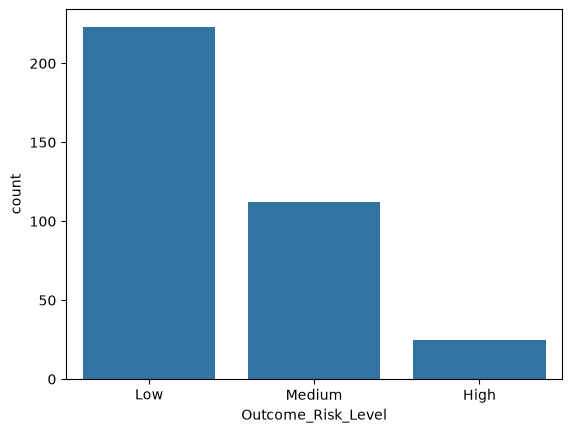

In [14]:
sns.countplot(
    x="Outcome_Risk_Level",
    data=df,
    order=["Low","Medium","High"]
)

<Axes: xlabel='Complexity_Score', ylabel='Count'>

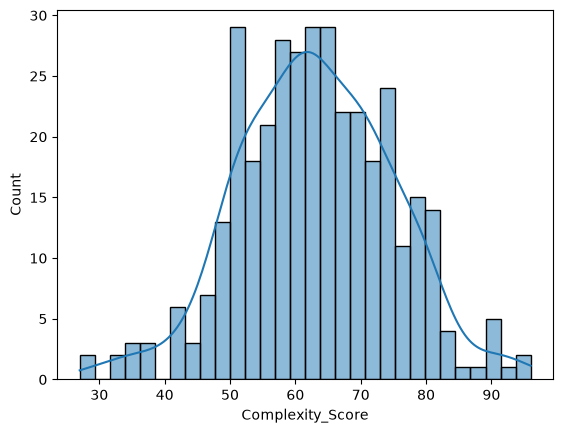

In [15]:
sns.histplot(
    df["Complexity_Score"],
    bins=30,
    kde=True
)


In [20]:
numeric_cols = df.select_dtypes(include = [np.int64, np.float64])
numeric_cols.corr()

,Complexity_Score,Planned_Duration_Days,Actual_Duration_Days,Delay_Days,Planned_Budget_USD,Actual_Budget_USD,Budget_Overrun_Pct,Team_Size,Critical_Path_Task_Count,Vendor_Count,Change_Order_Count,Resource_Buffer_Pct,Weather_Risk_Index,Procurement_Risk_Index,Stakeholder_Alignment_Score,Requirements_Volatility_Score,Forecast_Error_Days
Complexity_Score,1.000000,0.862535,0.841391,0.433313,0.886226,0.885338,0.394216,0.499290,0.476185,0.280692,0.075726,-0.368114,0.042470,0.028523,-0.460546,0.393470,0.305482
Planned_Duration_Days,0.862535,1.000000,0.946830,0.421606,0.766772,0.756550,0.304290,0.443898,0.598131,0.253753,0.035513,-0.326506,-0.011012,-0.009911,-0.390722,0.314643,0.269044
Actual_Duration_Days,0.841391,0.946830,1.000000,0.690931,0.746168,0.765129,0.387956,0.434372,0.553580,0.231439,0.064997,-0.343760,0.042241,0.077477,-0.431766,0.348573,0.424001
Delay_Days,0.433313,0.421606,0.690931,1.000000,0.380108,0.456517,0.409695,0.226821,0.216243,0.082120,0.103392,-0.235212,0.143797,0.240632,-0.338962,0.275433,0.590482
Planned_Budget_USD,0.886226,0.766772,0.746168,0.380108,1.000000,0.960914,0.308255,0.685157,0.410164,0.325838,0.054167,-0.312682,0.034718,0.038055,-0.429019,0.329089,0.323846
Actual_Budget_USD,0.885338,0.756550,0.765129,0.456517,0.960914,1.000000,0.555597,0.631144,0.420522,0.331079,0.115681,-0.335806,0.099669,0.121865,-0.436543,0.396254,0.375413
Budget_Overrun_Pct,0.394216,0.304290,0.387956,0.409695,0.308255,0.555597,1.000000,0.116265,0.222281,0.168721,0.249140,-0.206010,0.238534,0.302369,-0.208396,0.384102,0.275179
Team_Size,0.499290,0.443898,0.434372,0.226821,0.685157,0.631144,0.116265,1.000000,0.271837,0.176923,-0.008047,-0.146586,0.032193,0.009497,-0.249410,0.167635,0.234730
Critical_Path_Task_Count,0.476185,0.598131,0.553580,0.216243,0.410164,0.420522,0.222281,0.271837,1.000000,0.101066,0.115647,-0.162182,0.097182,0.094905,-0.215225,0.265862,0.124271
Vendor_Count,0.280692,0.253753,0.231439,0.082120,0.325838,0.331079,0.168721,0.176923,0.101066,1.000000,0.022768,-0.109976,0.040681,0.067729,-0.122333,0.037271,0.047307


<Axes: >

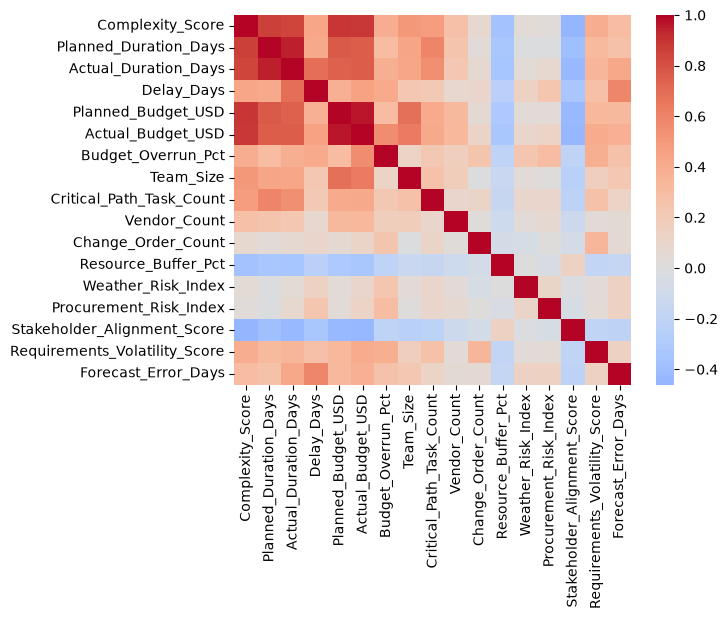

In [23]:
sns.heatmap(
    numeric_cols.corr(),
    cmap="coolwarm",
    center=0
)